In [1]:
%pip install qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# Import required libraries

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit.library import QFT
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt

# Define pi
pi = np.pi

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Create quantum register with 5 qubits
q = QuantumRegister(5, 'q')

# Create classical register with 5 classical bits
c = ClassicalRegister(5, 'c')

# Create quantum circuit
circuit = QuantumCircuit(q, c)

print("5-Qubit Quantum Circuit Created Successfully!")

5-Qubit Quantum Circuit Created Successfully!


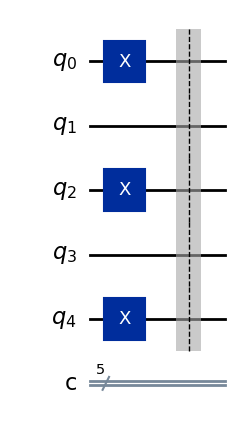

In [3]:
# Apply X gates to encode input state

circuit.x(q[4])
circuit.x(q[2])
circuit.x(q[0])

# Add barrier for better circuit visualization
circuit.barrier()

# Display circuit
display(circuit.draw(output='mpl'))

C:\Users\Aaditya\AppData\Local\Temp\ipykernel_1276\1129159831.py:2: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft = QFT(


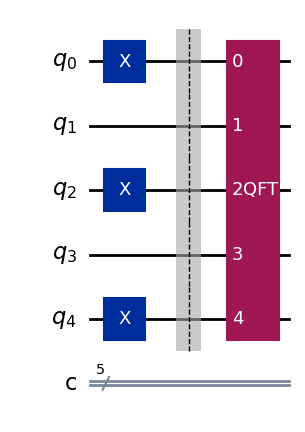

In [4]:
# Create 5-qubit QFT
qft = QFT(
    num_qubits=5,
    approximation_degree=0,
    do_swaps=True,
    inverse=False,
    insert_barriers=True,
    name='QFT'
)

# Apply QFT to the quantum circuit
circuit.compose(qft, qubits=q, inplace=True)

# Display circuit
display(circuit.draw(output='mpl'))

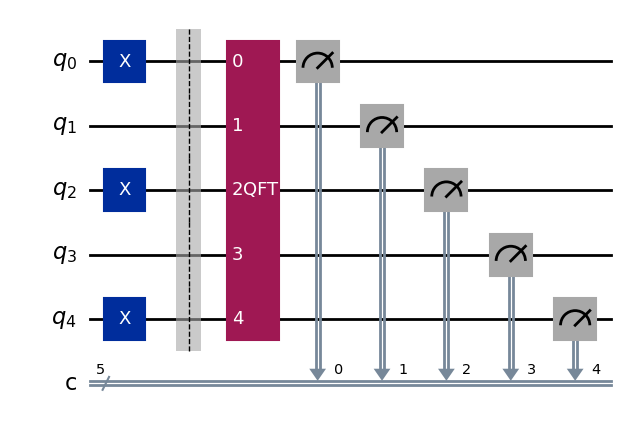

In [5]:
# Measure all 5 qubits
circuit.measure(q, c)

# Display complete QFT circuit
display(circuit.draw(output='mpl'))

In [6]:
# Create Aer simulator
simulator = AerSimulator()

# Transpile circuit for simulator
compiled_circuit = transpile(circuit, simulator)

# Execute circuit with 1000 shots
job = simulator.run(compiled_circuit, shots=1000)

# Get results
result = job.result()

# Get measurement counts
counts = result.get_counts()

# Display output
print("QFT Output")
print("----------------")
print(counts)

QFT Output
----------------
{'00001': 30, '01101': 16, '10001': 35, '01000': 43, '11001': 29, '10100': 35, '01110': 31, '10010': 33, '00111': 33, '00101': 28, '01010': 30, '01011': 30, '11101': 30, '00010': 31, '01100': 26, '00000': 29, '10011': 32, '01001': 39, '11111': 29, '11100': 30, '11010': 30, '10111': 30, '10000': 30, '11110': 31, '11011': 35, '11000': 35, '00011': 29, '00100': 31, '10110': 30, '01111': 32, '00110': 30, '10101': 38}


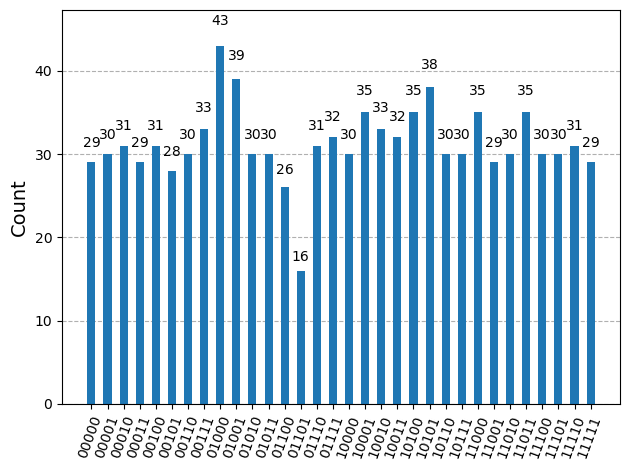

In [7]:
# Import display functions
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

# Generate measurement histogram
histogram = plot_histogram(counts)

# Display histogram
display(histogram)

# Close figure after displaying
plt.close(histogram)

C:\Users\Aaditya\AppData\Local\Temp\ipykernel_1276\1215479497.py:12: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  qft = QFT(
C:\Users\Aaditya\AppData\Local\Temp\ipykernel_1276\1215479497.py:25: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  iqft = QFT(


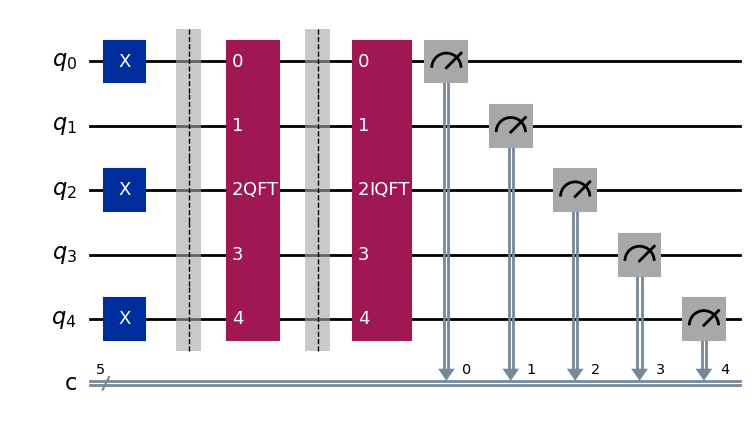

In [8]:
# Create a new 5-qubit circuit
inverse_circuit = QuantumCircuit(5, 5)

# Encode original input state 10101
inverse_circuit.x(4)
inverse_circuit.x(2)
inverse_circuit.x(0)

inverse_circuit.barrier()

# Apply QFT
qft = QFT(
    num_qubits=5,
    approximation_degree=0,
    do_swaps=True,
    inverse=False,
    insert_barriers=True
)

inverse_circuit.compose(qft, inplace=True)

inverse_circuit.barrier()

# Apply inverse QFT
iqft = QFT(
    num_qubits=5,
    approximation_degree=0,
    do_swaps=True,
    inverse=True,
    insert_barriers=True
)

inverse_circuit.compose(iqft, inplace=True)

# Measure all qubits
inverse_circuit.measure(range(5), range(5))

# Display inverse QFT circuit
display(inverse_circuit.draw(output='mpl'))

In [9]:
# Run inverse QFT circuit
compiled_iqft = transpile(inverse_circuit, simulator)

job_iqft = simulator.run(compiled_iqft, shots=1000)

result_iqft = job_iqft.result()

# Get measurement counts
iqft_counts = result_iqft.get_counts()

print("Inverse QFT Output")
print("-------------------")
print(iqft_counts)

Inverse QFT Output
-------------------
{'10101': 1000}


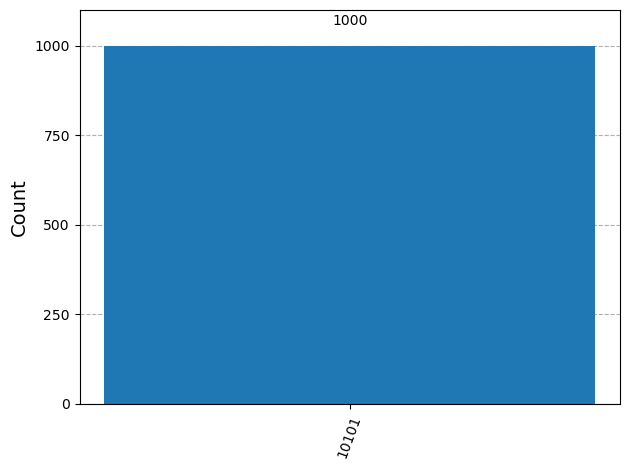

In [10]:
# Generate inverse QFT histogram
iqft_histogram = plot_histogram(iqft_counts)

# Display histogram
display(iqft_histogram)

plt.close(iqft_histogram)

In [11]:
# Expected input state in Qiskit's classical bit display order
expected_state = "10101"

# Find the most frequent measurement result
most_frequent = max(iqft_counts, key=iqft_counts.get)

print("Expected Original State:", expected_state)
print("Recovered State:", most_frequent)

if most_frequent == expected_state:
    print("Inverse QFT Successful!")
else:
    print("Check the circuit output.")

Expected Original State: 10101
Recovered State: 10101
Inverse QFT Successful!


In [ ]:
## 14. Algorithm
1. Start.
2. Import required Qiskit libraries.
3. Create a quantum circuit with five qubits and five classical bits.
4. Encode the input state 10101 using X gates.
5. Apply the 5-qubit Quantum Fourier Transform.
6. Measure all five qubits.
7. Execute the circuit using AerSimulator.
8. Display measurement counts.
9. Plot the measurement histogram.
10. Create another circuit for inverse QFT.
11. Apply QFT followed by inverse QFT.
12. Measure and verify the recovered state.
13. Stop.
15. Expected output
QFT circuit: A circuit containing Hadamard gates, controlled phase rotations and swap gates.

QFT histogram: Multiple measurement outcomes with different probabilities.

Inverse QFT histogram: The output should be concentrated at 10101.
Expected inverse QFT result: 10101
16. Conclusion
Thus, the 5-qubit Quantum Fourier Transform was successfully implemented using Python and Qiskit. The QFT transformed the input computational-basis state into the Fourier basis. The inverse QFT was also implemented to recover the original input state.

17. Viva questions and answers
Q1. What is QFT?

Quantum Fourier Transform is a quantum algorithm that transforms a quantum state from the computational basis to the Fourier basis.

Q2. What is the full form of QFT?

Quantum Fourier Transform.

Q3. What is the purpose of QFT?

It is used in quantum algorithms for phase estimation, factoring and finding periodicity.

Q4. How many qubits are used in this experiment?

Five qubits.

Q5. Which gates are used in QFT?

Hadamard gates, controlled phase rotation gates and swap gates.

Q6. What is a Hadamard gate?

It creates superposition between |0⟩ and |1⟩.

Q7. What is a controlled phase gate?

It applies a phase rotation to the target qubit depending on the control qubit.

Q8. What is inverse QFT?

It reverses the operation of QFT.

Q9. What is the use of swap gates?

They reverse the order of qubits at the end of the standard QFT circuit.

Q10. What is superposition?

It is the ability of a qubit to exist in a combination of quantum states.

Q11. What is entanglement?

It is a quantum phenomenon in which qubits become correlated and cannot be described independently.

Q12. What is AerSimulator?

It is a local quantum circuit simulator provided by Qiskit Aer.

Q13. What are shots?

Shots represent the number of times a quantum circuit is executed.

Q14. Why do we use 1000 shots?

To obtain measurement statistics over repeated circuit executions.

Q15. What is the use of a histogram?

It displays the frequency of different measurement outcomes.

Q16. What is the computational basis?

The standard qubit basis consisting of |0⟩ and |1⟩.

Q17. What does an X gate do?

It flips the qubit from |0⟩ to |1⟩ or vice versa.

Q18. What is the Fourier basis?

It is the basis formed by the Fourier-transformed computational basis states.

Q19. What is approximation degree?

It determines how many small controlled phase rotations can be omitted to reduce circuit depth.

Q20. Why is inverse QFT important?

It helps retrieve information encoded through the QFT transformation.

Q21. What is Qiskit?

Qiskit is an open-source Python framework for quantum computing.

Q22. What is a quantum register?

A collection of qubits used in a quantum circuit.

Q23. What is a classical register?

A collection of classical bits used to store measurement results.

Q24. Why do we use barriers?

To visually separate different stages of the circuit and help control compiler optimization.

Q25. What is the expected output of inverse QFT in this experiment?

The original state 10101.